### **Student Information**
GitHub ID:

Kaggle name:Jerrye Eng

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

# Project Report

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

The primary objective of preprocessing was to transform the raw social
media posts into a consistent format suitable for machine learning.
Unlike formal written documents, social media text often contains
informal expressions, URLs, user mentions, inconsistent capitalization,
and variations in writing styles. These characteristics can introduce
unnecessary noise into the feature extraction process.

To address these challenges, several preprocessing operations were
performed before developing the classification model.

**1. Data Loading and Integration**

The dataset consisted of four provided files: `data_identification.csv`,
`emotion.csv`, `final_posts.json`, and `sampleSubmission.csv`.

The files were loaded using Pandas and Python's JSON library. The post
identification information was merged with the actual text content using
`post_id` as the common identifier. The emotion labels were subsequently
joined with the training data.

To ensure data integrity, uniqueness checks were performed on the post
identifiers before merging.

After integrating the datasets, we obtained:

-   **3,360 labeled posts** for model training and validation.
-   **1,440 unlabeled posts** for final prediction and competition
    submission.

**2. Text Normalization**

Social media posts contain considerable variations in writing styles and
formatting. To reduce unnecessary differences between similar posts,
several normalization techniques were applied:

-   **Lowercase conversion:** Converted all text into lowercase so that
    words with different capitalization would be treated consistently.
-   **URL replacement:** Replaced URLs with a common token, `URLTOKEN`,
    instead of retaining different website addresses.
-   **User mention replacement:** Replaced usernames with `MENTIONTOKEN`
    to reduce unnecessary vocabulary variations while preserving the
    presence of a user mention.
-   **Whitespace normalization:** Reduced repeated whitespace to a
    single space to maintain a consistent text format.

These operations were implemented using regular expressions and a custom
text normalization function.

The original post content was retained in the dataset, while the
normalized version was stored separately in `text_clean`. This allowed
us to preserve the original information while using the cleaned text for
feature extraction.

**3. Training and Validation Split**

The labeled dataset was divided into training and validation subsets
using an 80:20 ratio.

We applied stratified sampling through `train_test_split` with
`stratify=y`. This was important because the classification task
involved six emotion categories. Without stratification, a random split
could result in different class proportions between the two subsets.

A fixed random state of 42 was used to ensure that the experiments could
be reproduced consistently.

**4. Emotion Distribution Analysis**

Before training the model, we examined the distribution of the six
emotion categories to understand the composition of the dataset.

![Emotion Class Distribution](./pics/class_distribution.png)

Understanding the class distribution is important because a model may
achieve reasonable overall accuracy while performing poorly on less
frequent emotion categories.

This observation motivated us to consider Macro F1 alongside accuracy
during model evaluation. We also experimented with balanced class
weights to investigate whether accounting for class frequency could
improve classification performance.

**5. Training and Validation Distribution**

![Training and Validation Distribution](./pics/train_valid.png)

The following plots provide additional views of text characteristics and model evaluation.

![Text Length Boxplot](./pics/boxplot.png)

![Model Configuration Comparison](./pics/model_comparison.png)

![Hyperparameter Tuning](./pics/hyperparameter_tuning.png)

![Confusion Matrix](./pics/confusion_matrix.png)

![Per-class F1 Score](./pics/per_class_f1.png)


The training and validation split was designed to evaluate the model on
data that was not used during its fitting process.

Using the same validation subset across our experiments allowed us to
compare different feature representations and model configurations under
consistent conditions.

------------------------------------------------------------------------

### 1.2 Feature Engineering Steps

After preprocessing, the next challenge was converting textual
information into numerical representations that could be processed by a
machine learning algorithm.

We selected **Term Frequency-Inverse Document Frequency (TF-IDF)** as
our primary feature extraction technique. TF-IDF represents the
importance of a term within a document relative to its frequency across
the document collection.

We experimented with word-level and character-level TF-IDF because
social media posts contain both meaningful word sequences and informal
spelling variations.

**1. Word-level TF-IDF**

The word-level vectorizer used unigrams and bigrams, configured with
`ngram_range=(1, 2)`. Unigrams represent individual words, while bigrams
represent consecutive two-word sequences. For example, "very happy" is
represented by both the individual words and the combined phrase.

The selected configuration used `min_df=2`, `max_df=0.99`,
`sublinear_tf=True`, and `strip_accents="unicode"`. These settings
filter terms that occur in very few documents or in almost all
documents, while applying logarithmic scaling to term frequency.

**2. Character-level TF-IDF**

We also tested character-level representations. Our initial baseline
used `analyzer="char"` with n-grams from 3 to 5 characters. In later
experiments, we tested `analyzer="char_wb"` with n-grams from 3 to 6
characters.

The `char_wb` analyzer extracts character n-grams within word
boundaries. This can help represent spelling variations, informal
expressions, and repeated characters without allowing n-grams to cross
from one word into another.

The selected configuration used `min_df=2`, `max_features=200000`, and
`sublinear_tf=True`.

**3. Combining Word-level and Character-level Features**

The word-level and character-level representations were combined using
Scikit-learn's `FeatureUnion`. In the selected configuration, both
feature groups had a weight of 1.0.

The combined representation allows the classifier to use complementary
information:

-   Word-level features capture vocabulary and short expressions.
-   Character-level features capture subword patterns and spelling
    variations.

We compared different word n-gram ranges and character analyzers rather
than assuming that adding more features would automatically improve
performance. The experiments showed that word bigrams combined with
`char_wb` character n-grams produced the strongest holdout validation
Macro F1 among the configurations tested.

**4. Feature Configuration Experiments**

We compared the following configurations:

| Configuration | Word features | Character features |
|---|---|---|
| Original TF-IDF | Unigrams and bigrams | `char`, 3–5 characters |
| Word Trigrams + Char WB | Unigrams, bigrams, and trigrams | `char_wb`, 3–6 characters |
| **Word Bigrams + Char WB** | **Unigrams and bigrams** | **`char_wb`, 3–6 characters** |
| Word Trigrams + Reduced Char Weight | Unigrams, bigrams, and trigrams | `char_wb`, 3–6 characters, weight 0.5 |

For the selected Word Bigrams + Char WB configuration, the word feature
weight and character feature weight were both 1.0. VADER sentiment
features were not included in the selected model.

------------------------------------------------------------------------

### 1.3 Explanation of Your Model

We selected **Linear Support Vector Classification (LinearSVC)** as our
classification algorithm.

LinearSVC is based on the Support Vector Machine (SVM) approach. It
learns linear decision boundaries that separate classes in the feature
space. In this project, each social media post is represented by a
high-dimensional, sparse TF-IDF feature vector, and LinearSVC learns the
relationship between these representations and the six emotion labels:

-   Anger
-   Disgust
-   Fear
-   Joy
-   Sadness
-   Surprise

For an unseen post, the classifier evaluates its learned decision
functions and predicts the emotion category with the highest decision
score.

**1. Why LinearSVC?**

TF-IDF produces high-dimensional and sparse feature matrices, where most
entries are zero. LinearSVC is a practical choice for this type of text
representation because it can efficiently learn linear decision
boundaries without requiring a computationally expensive nonlinear
kernel.

**2. Model Selection and Hyperparameter Tuning**

We conducted experiments to compare feature representations and
classifier settings. We used five-fold stratified cross-validation on
the training portion to tune the regularization parameter `C` and the
class-weighting option. The same held-out validation subset was then
used to compare the best cross-validation configuration from each
feature setup.

The `C` parameter controls the trade-off between regularization and
training errors. A smaller value applies stronger regularization, while
a larger value places more emphasis on minimizing training errors.

We tested:

`C = 0.05, 0.10, 0.25, 0.50`

We also compared `class_weight=None` with `class_weight="balanced"`.
Balanced class weights adjust the contribution of each class during
training according to its frequency in the training data.

**3. Experimental Results**

The following table summarizes the four feature configurations. The CV
Macro F1 column is the mean score from five-fold cross-validation.
Validation Accuracy and Validation Macro F1 are measured on the separate
20% holdout validation subset.

| Feature configuration | CV Macro F1 | Validation Accuracy | Validation Macro F1 | Best parameters |
|---|---:|---:|---:|---|
| Original TF-IDF | 0.4828 | 0.5387 | 0.5180 | `C=0.25`, balanced |
| Word Trigrams + Char WB | **0.4943** | 0.5595 | 0.5355 | `C=0.25`, balanced |
| **Word Bigrams + Char WB** | 0.4906 | **0.5655** | **0.5440** | **`C=0.10`, balanced** |
| Word Trigrams + Reduced Char Weight | 0.4821 | 0.5536 | 0.5312 | `C=0.50`, balanced |

Word Trigrams + Char WB achieved the highest mean cross-validation Macro
F1 (0.4943). However, Word Bigrams + Char WB achieved the highest Macro
F1 on the holdout validation subset (0.5440), as well as the highest
validation accuracy (0.5655). We selected Word Bigrams + Char WB as the
current final configuration based on its holdout validation Macro F1.

This distinction is important: the cross-validation score and holdout
validation score come from different evaluation procedures and should
not be treated as interchangeable. Since several configurations were
compared using the same holdout validation subset, the selected
validation result may be somewhat optimistic. The cross-validation
results provide an additional view of how consistently the
configurations perform across training folds.

**4. Selected Model Configuration**

The selected configuration is:

-   **Word features:** TF-IDF unigrams and bigrams, `min_df=2`,
    `max_df=0.99`.
-   **Character features:** TF-IDF using `analyzer="char_wb"` and
    n-grams from 3 to 6 characters.
-   **Feature combination:** `FeatureUnion`, with word and character
    weights both set to 1.0.
-   **Classifier:** LinearSVC.
-   **Regularization parameter:** `C=0.10`.
-   **Class weighting:** `class_weight="balanced"`.

The selected model achieved a holdout validation accuracy of **0.5655**
and a holdout validation Macro F1 of **0.5440**.

**5. Classification Error Analysis**

We examined the selected model's predictions using a confusion matrix.
Rows represent the actual emotion, while columns represent the predicted
emotion.

| Actual emotion ↓ / Predicted emotion → | Anger | Disgust | Fear | Joy | Sadness | Surprise |
|---|---:|---:|---:|---:|---:|---:|
| Anger | 70 | 17 | 11 | 17 | 11 | 9 |
| Disgust | 11 | 34 | 4 | 22 | 8 | 12 |
| Fear | 4 | 4 | 28 | 8 | 10 | 3 |
| Joy | 17 | 8 | 4 | 122 | 16 | 8 |
| Sadness | 17 | 4 | 4 | 19 | 76 | 6 |
| Surprise | 11 | 7 | 3 | 7 | 10 | 50 |

The model performed best on joy, while disgust was the most difficult
category. In particular, 22 disgust posts were predicted as joy. Fear
was also sometimes confused with sadness, with 10 fear posts assigned to
sadness.

These errors suggest that different emotion categories can share
vocabulary or appear in similar writing contexts. For example, a post
may contain positive-looking words while expressing criticism or another
negative emotion. TF-IDF primarily captures statistical word and
character patterns, so it may not fully represent sarcasm, context, or
the intended emotional meaning.

**6. Per-class Performance Analysis**

The per-class validation results were:

| Emotion | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Anger | 0.5385 | 0.5185 | 0.5283 | 135 |
| Disgust | 0.4595 | 0.3736 | 0.4121 | 91 |
| Fear | 0.5185 | 0.4912 | 0.5045 | 57 |
| Joy | 0.6256 | 0.6971 | 0.6595 | 175 |
| Sadness | 0.5802 | 0.6032 | 0.5914 | 126 |
| Surprise | 0.5682 | 0.5682 | 0.5682 | 88 |

The results show that joy had the highest F1 score (0.6595), while
disgust had the lowest (0.4121). This indicates that the model
recognizes some emotion categories more effectively than others. The
lower disgust recall suggests that many actual disgust posts are
assigned to other categories.

**7. Final Training and Competition Prediction**

After selecting the configuration using the training and validation
experiments, the final pipeline is refitted using all 3,360 labeled
posts. The fitted feature extractor transforms the 1,440 unlabeled test
posts using the vocabulary learned from the labeled training data, and
LinearSVC generates their predicted emotion labels.

The predictions are then matched with the provided submission template
using `post_id`, preserving the required column names and submission
order. The resulting file is saved as `submission.csv`.

The accuracy and Macro F1 values reported above are holdout validation
results. They are not the competition's private leaderboard score.

------------------------------------------------------------------------

### 1.4 AI Prompts, What and Why You Decided to Use the Techniques Suggested by AI

Throughout the development process, ChatGPT was used as a supporting
tool to explore possible approaches, clarify machine learning concepts,
and assist with experimental decisions.

Rather than accepting every recommendation directly, we treated AI
suggestions as starting points and evaluated their usefulness through
implementation and validation experiments.

**1. Preprocessing Strategy**

We discussed suitable preprocessing techniques for social media text
classification, particularly how to handle URLs, user mentions,
capitalization, and inconsistent text formatting.

Based on these discussions, we implemented lowercase conversion, URL
replacement, mention replacement, and whitespace normalization. These
operations were selected to reduce unnecessary vocabulary variations
while retaining the presence of URLs and user mentions through
placeholder tokens.

**2. Feature Engineering and Text Representation**

We used AI assistance to understand the differences between word-level
and character-level TF-IDF and to consider how each representation might
capture different characteristics of social media text.

We tested word n-grams, character n-grams, and the `char_wb` analyzer.
The experiments showed that Word Bigrams + Char WB achieved the highest
holdout validation Macro F1 among the tested feature configurations.
This result supported retaining both word-level and character-level
information rather than relying on word features alone.

**3. Model Selection and Class Weighting**

AI was used to clarify why LinearSVC is suitable for high-dimensional
sparse TF-IDF features and how class weighting can affect classification
performance.

We compared `class_weight=None` and `class_weight="balanced"` rather
than assuming that balancing would necessarily help. The best parameters
for the selected feature configuration were `C=0.10` and
`class_weight="balanced"`.

**4. Cross-validation and Evaluation**

We discussed the use of Macro F1 in a six-class classification task and
why accuracy alone may not describe performance across all emotion
categories.

We also used confusion-matrix analysis to identify frequent
classification errors. The results showed that disgust was often
confused with joy, while fear was sometimes confused with sadness. These
observations helped us identify weaknesses that are not obvious from the
overall accuracy score.

**5. Reflection on AI-assisted Development**

AI was primarily used to support technical understanding, suggest
experiments, and help interpret model results. We did not adopt every
suggested technique automatically. Instead, we implemented candidate
approaches and compared their results using the same data split and
evaluation metrics.

The experiments demonstrated that a theoretically more complex feature
representation does not necessarily perform better. For example, adding
word trigrams did not outperform the word-bigram configuration on the
holdout validation Macro F1.

Overall, AI served as a technical assistant throughout the project,
while the responsibility for evaluating results, comparing alternatives,
and selecting the model remained with us.


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [7]:
### Add the code related to the preprocessing steps in cells inside this section


from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC

RANDOM_STATE = 42

# Access the local competition dataset folder
DATA_DIR = Path(
    r"C:\Users\User\Documents\lab2\DM2026-Lab2-Exercise\2026-dm-lab-2-private-competition"
)

print("Competition data path:", DATA_DIR)

# Check that the folder exists
assert DATA_DIR.exists(), f"Folder not found: {DATA_DIR}"

# Load the provided files
identification = pd.read_csv(DATA_DIR / "data_identification.csv")
emotions = pd.read_csv(DATA_DIR / "emotion.csv")
submission_template = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

with open(DATA_DIR / "final_posts.json", "r", encoding="utf-8") as f:
    posts = pd.DataFrame(json.load(f))

# Validate unique identifiers
assert identification["post_id"].is_unique
assert emotions["post_id"].is_unique
assert posts["post_id"].is_unique

# Combine post text with train/test identification
all_data = identification.merge(
    posts,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Separate training and testing data
train_df = all_data[all_data["set"] == "train"].copy()
test_df = all_data[all_data["set"] == "test"].copy()

# Attach emotion labels to training data
train_df = train_df.merge(
    emotions,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Check missing values
assert train_df["text"].notna().all()
assert train_df["label"].notna().all()
assert test_df["text"].notna().all()

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

# Inspect emotion distribution
print("\nEmotion distribution:")
display(train_df["label"].value_counts())

# Text normalization
URL_PATTERN = re.compile(
    r"https?://\S+|www\.\S+",
    flags=re.IGNORECASE
)

MENTION_PATTERN = re.compile(
    r"(?<!\w)@[A-Za-z0-9_]+"
)

def normalize_text(text):
    text = str(text).lower()
    text = URL_PATTERN.sub(" URLTOKEN ", text)
    text = MENTION_PATTERN.sub(" MENTIONTOKEN ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["text_clean"] = train_df["text"].apply(normalize_text)
test_df["text_clean"] = test_df["text"].apply(normalize_text)

# Create a stratified validation split
X = train_df["text_clean"]
y = train_df["label"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining split:", len(X_train))
print("Validation split:", len(X_valid))


Competition data path: C:\Users\User\Documents\lab2\DM2026-Lab2-Exercise\2026-dm-lab-2-private-competition
Training data: (3360, 4)
Testing data: (1440, 3)

Emotion distribution:


label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


Training split: 2688
Validation split: 672


## 2. Feature Engineering Steps

In [13]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone
import pandas as pd

RANDOM_STATE = 42

# --------------------------------------------------
# 1. Define feature engineering configurations
# --------------------------------------------------

def make_features(config):

    word_features = TfidfVectorizer(
        analyzer="word",
        ngram_range=config["word_ngram"],
        min_df=config["word_min_df"],
        max_df=config["max_df"],
        sublinear_tf=True,
        strip_accents="unicode"
    )

    char_features = TfidfVectorizer(
        analyzer=config["char_analyzer"],
        ngram_range=config["char_ngram"],
        min_df=2,
        max_features=200_000,
        sublinear_tf=True
    )

    return FeatureUnion(
        [
            ("word", word_features),
            ("char", char_features)
        ],
        transformer_weights=config["weights"]
    )


configs = {
    "Original TF-IDF": {
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "max_df": 0.98,
        "char_analyzer": "char",
        "char_ngram": (3, 5),
        "weights": {"word": 1.0, "char": 1.0}
    },

    "Word Trigrams + Char WB": {
        "word_ngram": (1, 3),
        "word_min_df": 1,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 1.0}
    },

    "Word Bigrams + Char WB": {
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 1.0}
    },

    "Word Trigrams + Reduced Char Weight": {
        "word_ngram": (1, 3),
        "word_min_df": 1,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 0.5}
    }
}


# --------------------------------------------------
# 2. Cross-validation configuration
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

results = []
searches = {}

# --------------------------------------------------
# 3. Tune each feature configuration
# --------------------------------------------------

for name, config in configs.items():

    print("\n" + "=" * 55)
    print("Testing:", name)
    print("=" * 55)

    pipeline = Pipeline([
        ("features", make_features(config)),
        ("classifier", LinearSVC(
            random_state=RANDOM_STATE
        ))
    ])

    param_grid = {
        "classifier__C": [0.05, 0.1, 0.25, 0.5],
        "classifier__class_weight": [None, "balanced"]
    }

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=1,
        refit=True,
        verbose=0
    )

    search.fit(X_train, y_train)

    # Evaluate the best CV model on the untouched validation split
    predictions = search.predict(X_valid)

    accuracy = accuracy_score(y_valid, predictions)
    macro_f1 = f1_score(
        y_valid,
        predictions,
        average="macro"
    )

    searches[name] = search

    results.append({
        "Configuration": name,
        "CV Macro F1": search.best_score_,
        "Validation Accuracy": accuracy,
        "Validation Macro F1": macro_f1,
        "Best Parameters": search.best_params_
    })

    print("Best CV Macro F1:", round(search.best_score_, 4))
    print("Validation Accuracy:", round(accuracy, 4))
    print("Validation Macro F1:", round(macro_f1, 4))
    print("Best Parameters:", search.best_params_)


# --------------------------------------------------
# 4. Compare all configurations
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df)

# Select the best configuration using validation Macro F1
best_config_name = results_df.iloc[0]["Configuration"]
best_search = searches[best_config_name]

print("\nBEST CONFIGURATION:", best_config_name)
print("Best validation Macro F1:",
      round(results_df.iloc[0]["Validation Macro F1"], 4))

# Detailed classification report
from sklearn.metrics import classification_report

best_predictions = best_search.predict(X_valid)

print("\nClassification Report:")
print(classification_report(
    y_valid,
    best_predictions,
    digits=4,
    zero_division=0
))



Testing: Original TF-IDF
Best CV Macro F1: 0.4828
Validation Accuracy: 0.5387
Validation Macro F1: 0.518
Best Parameters: {'classifier__C': 0.25, 'classifier__class_weight': 'balanced'}

Testing: Word Trigrams + Char WB
Best CV Macro F1: 0.4943
Validation Accuracy: 0.5595
Validation Macro F1: 0.5355
Best Parameters: {'classifier__C': 0.25, 'classifier__class_weight': 'balanced'}

Testing: Word Bigrams + Char WB
Best CV Macro F1: 0.4906
Validation Accuracy: 0.5655
Validation Macro F1: 0.544
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Testing: Word Trigrams + Reduced Char Weight
Best CV Macro F1: 0.4821
Validation Accuracy: 0.5536
Validation Macro F1: 0.5312
Best Parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced'}


,Configuration,CV Macro F1,Validation Accuracy,Validation Macro F1,Best Parameters
0,Word Bigrams + Char WB,0.490604,0.565476,0.544001,"{'classifier__C': 0.1, 'classifier__class_weig..."
1,Word Trigrams + Char WB,0.494278,0.559524,0.535460,"{'classifier__C': 0.25, 'classifier__class_wei..."
2,Word Trigrams + Reduced Char Weight,0.482092,0.553571,0.531212,"{'classifier__C': 0.5, 'classifier__class_weig..."
3,Original TF-IDF,0.482767,0.538690,0.517961,"{'classifier__C': 0.25, 'classifier__class_wei..."



BEST CONFIGURATION: Word Bigrams + Char WB
Best validation Macro F1: 0.544

Classification Report:
              precision    recall  f1-score   support

       anger     0.5385    0.5185    0.5283       135
     disgust     0.4595    0.3736    0.4121        91
        fear     0.5185    0.4912    0.5045        57
         joy     0.6256    0.6971    0.6595       175
     sadness     0.5802    0.6032    0.5914       126
    surprise     0.5682    0.5682    0.5682        88

    accuracy                         0.5655       672
   macro avg     0.5484    0.5420    0.5440       672
weighted avg     0.5605    0.5655    0.5618       672



## 3. Model Implementation Steps


Testing feature configuration: Original TF-IDF
Best CV Macro F1: 0.4828
Validation Accuracy: 0.5387
Validation Macro F1: 0.5180
Best parameters: {'classifier__C': 0.25, 'classifier__class_weight': 'balanced'}

Testing feature configuration: Word Trigrams + Char WB
Best CV Macro F1: 0.4943
Validation Accuracy: 0.5595
Validation Macro F1: 0.5355
Best parameters: {'classifier__C': 0.25, 'classifier__class_weight': 'balanced'}

Testing feature configuration: Word Bigrams + Char WB
Best CV Macro F1: 0.4906
Validation Accuracy: 0.5655
Validation Macro F1: 0.5440
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Testing feature configuration: Word Trigrams + Reduced Char Weight
Best CV Macro F1: 0.4821
Validation Accuracy: 0.5536
Validation Macro F1: 0.5312
Best parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced'}

FEATURE AND MODEL COMPARISON


,Configuration,CV Macro F1,Validation Accuracy,Validation Macro F1,Best C,Class Weight
0,Word Bigrams + Char WB,0.4906,0.5655,0.5440,0.10,balanced
1,Word Trigrams + Char WB,0.4943,0.5595,0.5355,0.25,balanced
2,Word Trigrams + Reduced Char Weight,0.4821,0.5536,0.5312,0.50,balanced
3,Original TF-IDF,0.4828,0.5387,0.5180,0.25,balanced



SELECTED CONFIGURATION
Feature configuration: Word Bigrams + Char WB
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Validation accuracy: 0.5655
Validation Macro F1: 0.5440

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       anger     0.5385    0.5185    0.5283       135
     disgust     0.4595    0.3736    0.4121        91
        fear     0.5185    0.4912    0.5045        57
         joy     0.6256    0.6971    0.6595       175
     sadness     0.5802    0.6032    0.5914       126
    surprise     0.5682    0.5682    0.5682        88

    accuracy                         0.5655       672
   macro avg     0.5484    0.5420    0.5440       672
weighted avg     0.5605    0.5655    0.5618       672



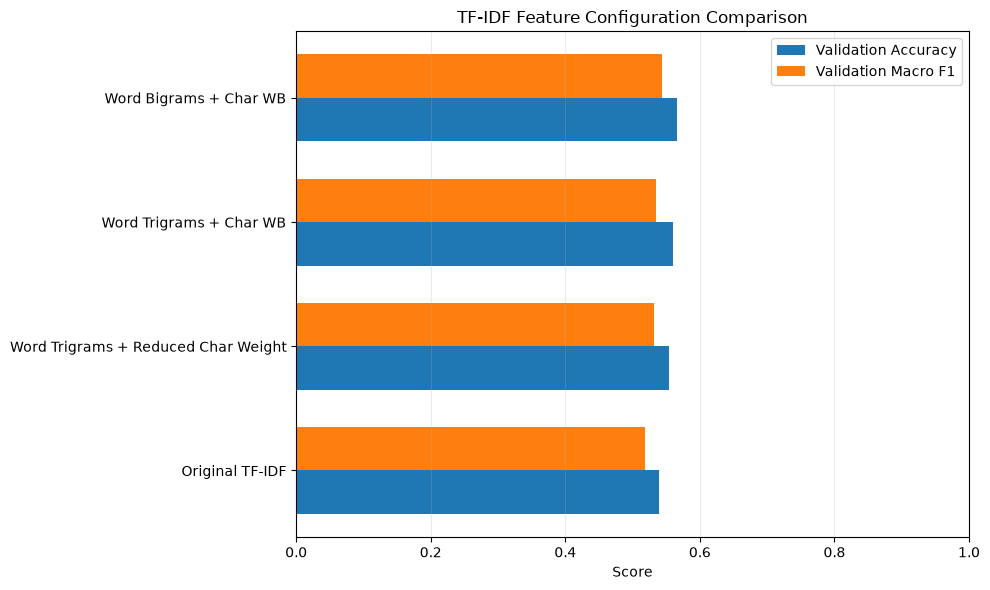

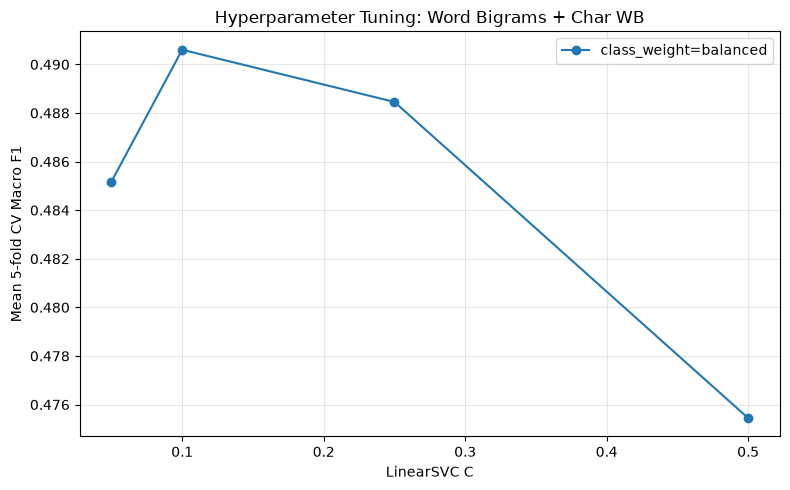

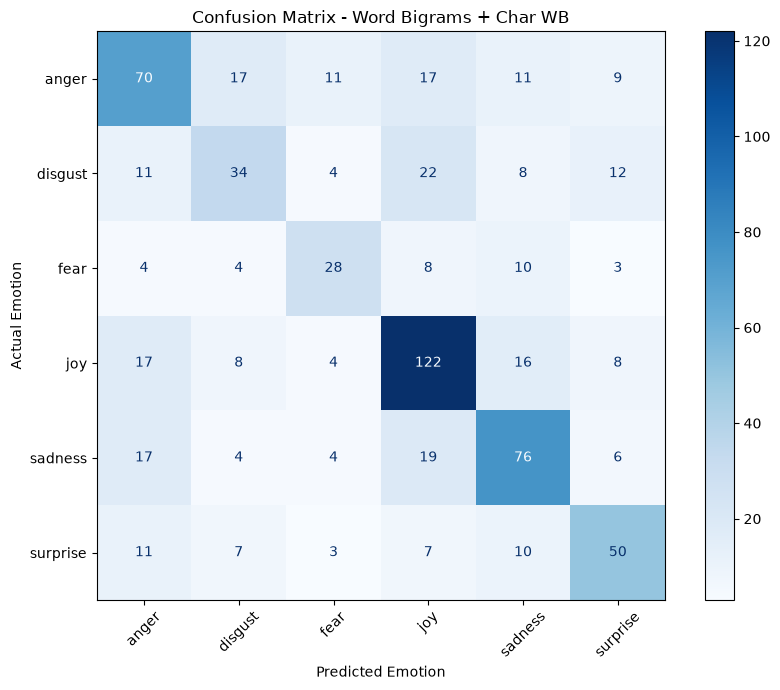

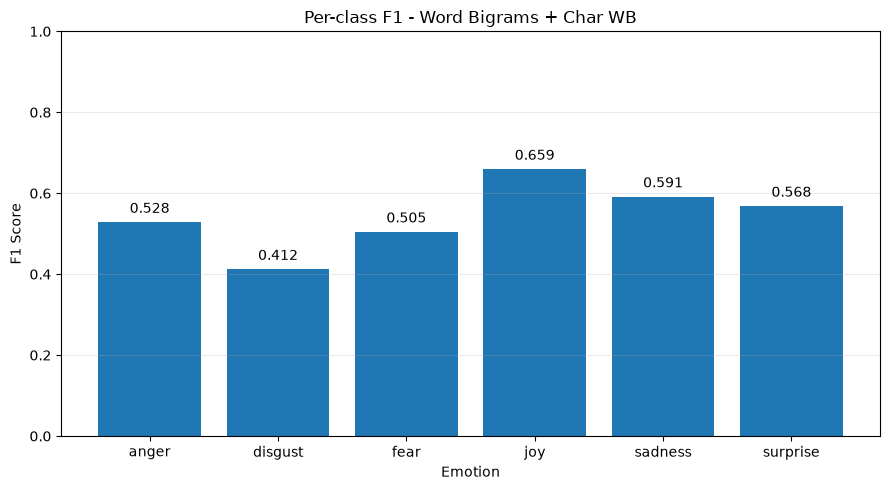


TRAINING FINAL MODEL ON ALL LABELED POSTS
Final model training completed.

SUBMISSION CREATED
Submission shape: (1440, 2)
Prediction distribution:


label
joy         391
anger       316
sadness     268
surprise    182
disgust     163
fear        120
Name: count, dtype: int64

,post_id,label
0,xyzx9jp,anger
1,l3vzzxt,fear
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise



Generated files:
boxplot.png
class_distribution.png
confusion_matrix.png
cosine_similarity.png
example_md_img.png
hyperparameter_tuning.png
model_comparison.png
model_comparison_results.csv
per_class_f1.png
pic_ranking.png
train_valid.png
submission.csv


In [19]:
# ============================================================
# 1. MODEL IMPLEMENTATION AND EXPERIMENTATION
#    No VADER: use TF-IDF features only.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
PICS_DIR = Path("pics")
PICS_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. DEFINE THE FEATURE CONFIGURATIONS
# ============================================================

def make_features(config):
    """Create word-level and character-level TF-IDF features."""

    word_features = TfidfVectorizer(
        analyzer="word",
        ngram_range=config["word_ngram"],
        min_df=config["word_min_df"],
        max_df=config["max_df"],
        sublinear_tf=True,
        strip_accents="unicode"
    )

    char_features = TfidfVectorizer(
        analyzer=config["char_analyzer"],
        ngram_range=config["char_ngram"],
        min_df=2,
        max_features=200_000,
        sublinear_tf=True
    )

    return FeatureUnion(
        [
            ("word", word_features),
            ("char", char_features)
        ],
        transformer_weights=config["weights"]
    )


feature_configs = {
    "Original TF-IDF": {
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "max_df": 0.98,
        "char_analyzer": "char",
        "char_ngram": (3, 5),
        "weights": {"word": 1.0, "char": 1.0}
    },
    "Word Trigrams + Char WB": {
        "word_ngram": (1, 3),
        "word_min_df": 1,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 1.0}
    },
    "Word Bigrams + Char WB": {
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 1.0}
    },
    "Word Trigrams + Reduced Char Weight": {
        "word_ngram": (1, 3),
        "word_min_df": 1,
        "max_df": 0.99,
        "char_analyzer": "char_wb",
        "char_ngram": (3, 6),
        "weights": {"word": 1.0, "char": 0.5}
    }
}


# ============================================================
# 3. CROSS-VALIDATION AND HYPERPARAMETER SEARCH
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid = {
    "classifier__C": [0.05, 0.1, 0.25, 0.5],
    "classifier__class_weight": [None, "balanced"]
}

searches = {}
experiment_rows = []

for config_name, config in feature_configs.items():
    print("\n" + "=" * 65)
    print("Testing feature configuration:", config_name)
    print("=" * 65)

    pipeline = Pipeline([
        ("features", make_features(config)),
        ("classifier", LinearSVC(random_state=RANDOM_STATE))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=1,
        refit=True,
        verbose=0
    )

    # Hyperparameter tuning uses X_train only.
    search.fit(X_train, y_train)

    # X_valid is held out from fitting and used for final comparison.
    valid_predictions = search.predict(X_valid)
    valid_accuracy = accuracy_score(y_valid, valid_predictions)
    valid_macro_f1 = f1_score(
        y_valid,
        valid_predictions,
        average="macro"
    )

    searches[config_name] = search
    experiment_rows.append({
        "Configuration": config_name,
        "CV Macro F1": search.best_score_,
        "Validation Accuracy": valid_accuracy,
        "Validation Macro F1": valid_macro_f1,
        "Best C": search.best_params_["classifier__C"],
        "Class Weight": search.best_params_["classifier__class_weight"]
    })

    print("Best CV Macro F1:", f"{search.best_score_:.4f}")
    print("Validation Accuracy:", f"{valid_accuracy:.4f}")
    print("Validation Macro F1:", f"{valid_macro_f1:.4f}")
    print("Best parameters:", search.best_params_)


# ============================================================
# 4. COMPARE CONFIGURATIONS AND SELECT THE BEST ONE
# ============================================================

comparison = pd.DataFrame(experiment_rows).sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nFEATURE AND MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    PICS_DIR / "model_comparison_results.csv",
    index=False
)

# Keep the same selection criterion used in our previous experiments:
# highest held-out validation Macro F1.
best_config_name = comparison.iloc[0]["Configuration"]
best_search = searches[best_config_name]
best_predictions = best_search.predict(X_valid)

print("\nSELECTED CONFIGURATION")
print("Feature configuration:", best_config_name)
print("Best parameters:", best_search.best_params_)
print("Validation accuracy:", f"{accuracy_score(y_valid, best_predictions):.4f}")
print("Validation Macro F1:", f"{f1_score(y_valid, best_predictions, average='macro'):.4f}")


# ============================================================
# 5. CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_valid,
    best_predictions,
    digits=4,
    zero_division=0
))


# ============================================================
# 6. VISUALIZATION: MODEL COMPARISON
# ============================================================

plot_data = comparison.sort_values(
    by="Validation Macro F1",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))
y_positions = np.arange(len(plot_data))
bar_height = 0.35

ax.barh(
    y_positions - bar_height / 2,
    plot_data["Validation Accuracy"],
    bar_height,
    label="Validation Accuracy"
)
ax.barh(
    y_positions + bar_height / 2,
    plot_data["Validation Macro F1"],
    bar_height,
    label="Validation Macro F1"
)
ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Configuration"])
ax.set_xlim(0, 1)
ax.set_xlabel("Score")
ax.set_title("TF-IDF Feature Configuration Comparison")
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(PICS_DIR / "model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 7. VISUALIZATION: C AND CLASS-WEIGHT TUNING
# ============================================================

best_cv_results = pd.DataFrame(best_search.cv_results_)
best_cv_results["C"] = best_cv_results["param_classifier__C"].astype(float)
best_cv_results["class_weight"] = best_cv_results[
    "param_classifier__class_weight"
].astype(str)

fig, ax = plt.subplots(figsize=(8, 5))
for weight_name, group in best_cv_results.groupby("class_weight"):
    group = group.sort_values("C")
    ax.plot(
        group["C"],
        group["mean_test_score"],
        marker="o",
        label=f"class_weight={weight_name}"
    )

ax.set_xlabel("LinearSVC C")
ax.set_ylabel("Mean 5-fold CV Macro F1")
ax.set_title(f"Hyperparameter Tuning: {best_config_name}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PICS_DIR / "hyperparameter_tuning.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 8. VISUALIZATION: CONFUSION MATRIX
# ============================================================

labels = sorted(pd.Series(y_train).unique())
cm = confusion_matrix(y_valid, best_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=True
)
ax.set_title(f"Confusion Matrix - {best_config_name}")
ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("Actual Emotion")
plt.tight_layout()
plt.savefig(PICS_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 9. VISUALIZATION: PER-CLASS F1
# ============================================================

report_dict = classification_report(
    y_valid,
    best_predictions,
    output_dict=True,
    zero_division=0
)

class_f1 = pd.Series({
    label: report_dict[label]["f1-score"]
    for label in labels
})

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(class_f1.index, class_f1.values)
ax.set_title(f"Per-class F1 - {best_config_name}")
ax.set_xlabel("Emotion")
ax.set_ylabel("F1 Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)

for bar, score in zip(bars, class_f1.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{score:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(PICS_DIR / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 10. REFIT THE SELECTED PIPELINE ON ALL LABELED DATA
# ============================================================

print("\nTRAINING FINAL MODEL ON ALL LABELED POSTS")
final_model = clone(best_search.best_estimator_)
final_model.fit(
    train_df["text_clean"],
    train_df["label"]
)
print("Final model training completed.")


# ============================================================
# 11. PREDICT TEST POSTS AND CREATE SUBMISSION
# ============================================================

test_predictions = final_model.predict(test_df["text_clean"])

prediction_map = pd.DataFrame({
    "post_id": test_df["post_id"].values,
    "label": test_predictions
})

# Preserve the exact order of the provided submission template.
submission = submission_template[["post_id"]].merge(
    prediction_map,
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == len(submission_template)
assert submission["post_id"].is_unique
assert submission["label"].notna().all()
assert submission.columns.tolist() == ["post_id", "label"]

submission.to_csv("submission.csv", index=False)

print("\nSUBMISSION CREATED")
print("Submission shape:", submission.shape)
print("Prediction distribution:")
display(submission["label"].value_counts())
display(submission.head())

print("\nGenerated files:")
for file in sorted(PICS_DIR.iterdir()):
    print(file.name)
print("submission.csv")
